In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier

In [186]:
df = pd.read_csv("survey.csv", sep=';')
print(df.shape)
df.head()

(1259, 27)


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,27.08.2014 11:29,37,Female,United States,IL,NaN,No,Yes,Often,45809,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,27.08.2014 11:29,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,27.08.2014 11:29,32,Male,Canada,NaN,NaN,No,No,Rarely,45809,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,27.08.2014 11:29,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,27.08.2014 11:30,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [187]:
# drop last and first column
df.drop(df.columns[0], axis=1, inplace=True)
df.drop(df.columns[-1], axis=1, inplace=True)

# show column names with missing values along with their types
for col in df.columns:
    if df[col].isna().sum() > 0:
        print(col, df[col].dtype, df[col].isna().sum())
print('\n')

# list unique values in each column to determine stupid values
for col in df.columns:
    print(col, df[col].unique())
    print('\n')

state str 515
self_employed str 18
work_interfere str 264


Age [         37          44          32          31          33          35
          39          42          23          29          36          27
          46          41          34          30          40          38
          50          24          18          28          26          22
          19          25          45          21         -29          43
          56          60          54         329          55 99999999999
          48          20          57          58          47          62
          51          65          49       -1726           5          53
          61           8          11          -1          72]


Gender <StringArray>
[                                       'Female',
                                             'M',
                                          'Male',
                                          'male',
                                        'female',
                 

In [188]:
# apply missing value handling strategy for each column with missing values

# drop rows with age below 18 and above 100
df = df[(df['Age'] >= 18) & (df['Age'] <= 100)]

# sort gender column by assigning 3 unique values: female, male, other
drop_values = ['Nah', 'A little about you', 'p']
df = df[~df['Gender'].isin(drop_values)].copy()
df['Gender'] = df['Gender'].str.lower().str.strip()

male_terms = [
    'm', 'male', 'male-ish', 'maile', 'something kinda male?', 'cis male', 
    'mal', 'male (cis)', 'make', 'guy (-ish) ^_^', 'male leaning androgynous', 
    'man', 'msle', 'mail', 'malr', 'cis man', 
    'ostensibly male unsure what that really means'
]

female_terms = [
    'female', 'trans-female', 'cis female', 'f', 'woman', 'femake', 
    'cis-female/femme', 'trans woman', 'female (trans)', 'female (cis)', 'femail'
]

other_terms = [
    'queer/she/they', 'non-binary', 'all', 'enby', 'fluid', 'genderqueer', 
    'androgyne', 'agender', 'neuter', 'queer'
]

category_mapping = {}
for term in male_terms: category_mapping[term] = 'Male'
for term in female_terms: category_mapping[term] = 'Female'
for term in other_terms: category_mapping[term] = 'Other'
df['Gender'] = df['Gender'].map(category_mapping)

# substitute missing values in self_employed column with mode
mode_value = df['self_employed'].mode()[0]
df['self_employed'] = df['self_employed'].fillna(mode_value)

# substitute missing values in work_interfere column with new value 'no_illness'
df['work_interfere'] = df['work_interfere'].fillna('no_illness')

# substitute missing values in state column with 'not_US'
df['state'] = df['state'].fillna('not_US')

# due to silly excel properties, like exchanging interval 6-25 with date june 2025, adjustments need to be made in no_employees column
df['no_employees'] = df['no_employees'].replace({'45809': '6-25', '46143': '1-5'})

In [189]:
# check if there are still missing values
print(df.isna().sum(), '\n')
for col in df.columns:
    print(col, df[col].unique())
    print('\n')

# print number of samples
print("Number of samples:", df.shape[0])

Age                          0
Gender                       0
Country                      0
state                        0
self_employed                0
family_history               0
treatment                    0
work_interfere               0
no_employees                 0
remote_work                  0
tech_company                 0
benefits                     0
care_options                 0
wellness_program             0
seek_help                    0
anonymity                    0
leave                        0
mental_health_consequence    0
phys_health_consequence      0
coworkers                    0
supervisor                   0
mental_health_interview      0
phys_health_interview        0
mental_vs_physical           0
obs_consequence              0
dtype: int64 

Age [37 44 32 31 33 35 39 42 23 29 36 27 46 41 34 30 40 38 50 24 18 28 26 22
 19 25 45 21 43 56 60 54 55 48 20 57 58 47 62 51 65 49 53 61 72]


Gender <StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype:

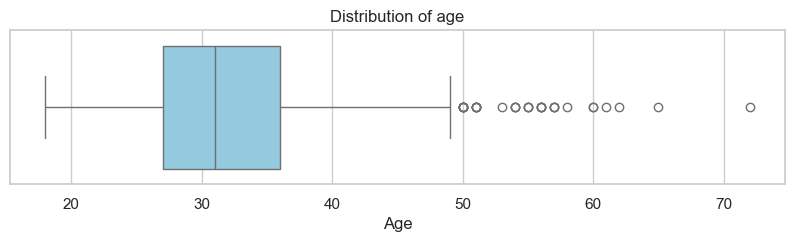

count    1250.000000
mean       32.079200
std         7.290669
min        18.000000
25%        27.000000
50%        31.000000
75%        36.000000
max        72.000000
Name: Age, dtype: float64 

Moderate outliers: 32
Extreme outliers: 2


In [190]:
# Age column outliers detection and handling

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 1, figsize=(10, 2))
sns.boxplot(data=df, x='Age', color='skyblue')
plt.title('Distribution of age')
plt.show()

# show summary statistics for age column
print(df['Age'].describe(), '\n')

# determine moderate and extreme outliers using IQR method
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
extreme_lower_bound = Q1 - 3 * IQR
extreme_upper_bound = Q3 + 3 * IQR
print(f'Moderate outliers: {df[(df["Age"] < lower_bound) | (df["Age"] > upper_bound)].shape[0]}')
print(f'Extreme outliers: {df[(df["Age"] < extreme_lower_bound) | (df["Age"] > extreme_upper_bound)].shape[0]}')

# # delete all outliers from age column
# df = df[(df["Age"] >= lower_bound) & (df["Age"] <= upper_bound)]
# print(f'Rows remaining after removing outliers: {df.shape[0]}')

# fig, axes = plt.subplots(1, 1, figsize=(10, 2))
# sns.boxplot(data=df, x='Age', color='skyblue')
# plt.title('Distribution of age')
# plt.show()

# # show summary statistics for age column after outliers removal
# print(df['Age'].describe(), '\n')

In [191]:
# display count per country
country_counts = df['Country'].value_counts()
print(country_counts)

Country
United States             745
United Kingdom            184
Canada                     72
Germany                    45
Netherlands                27
Ireland                    27
Australia                  21
France                     13
India                      10
New Zealand                 8
Switzerland                 7
Poland                      7
Italy                       7
Sweden                      7
Brazil                      6
South Africa                6
Belgium                     6
Israel                      5
Bulgaria                    4
Singapore                   4
Russia                      3
Mexico                      3
Austria                     3
Finland                     3
Portugal                    2
Colombia                    2
Croatia                     2
Denmark                     2
Greece                      2
Slovenia                    1
Costa Rica                  1
Latvia                      1
Romania                     1
Sp

C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\3155199053.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', ax=axes[0, 1], palette='Set2')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\3155199053.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='no_employees', order=size_order, ax=axes[1, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\3155199053.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='work_interfere', order=interfere_order, ax=axes[

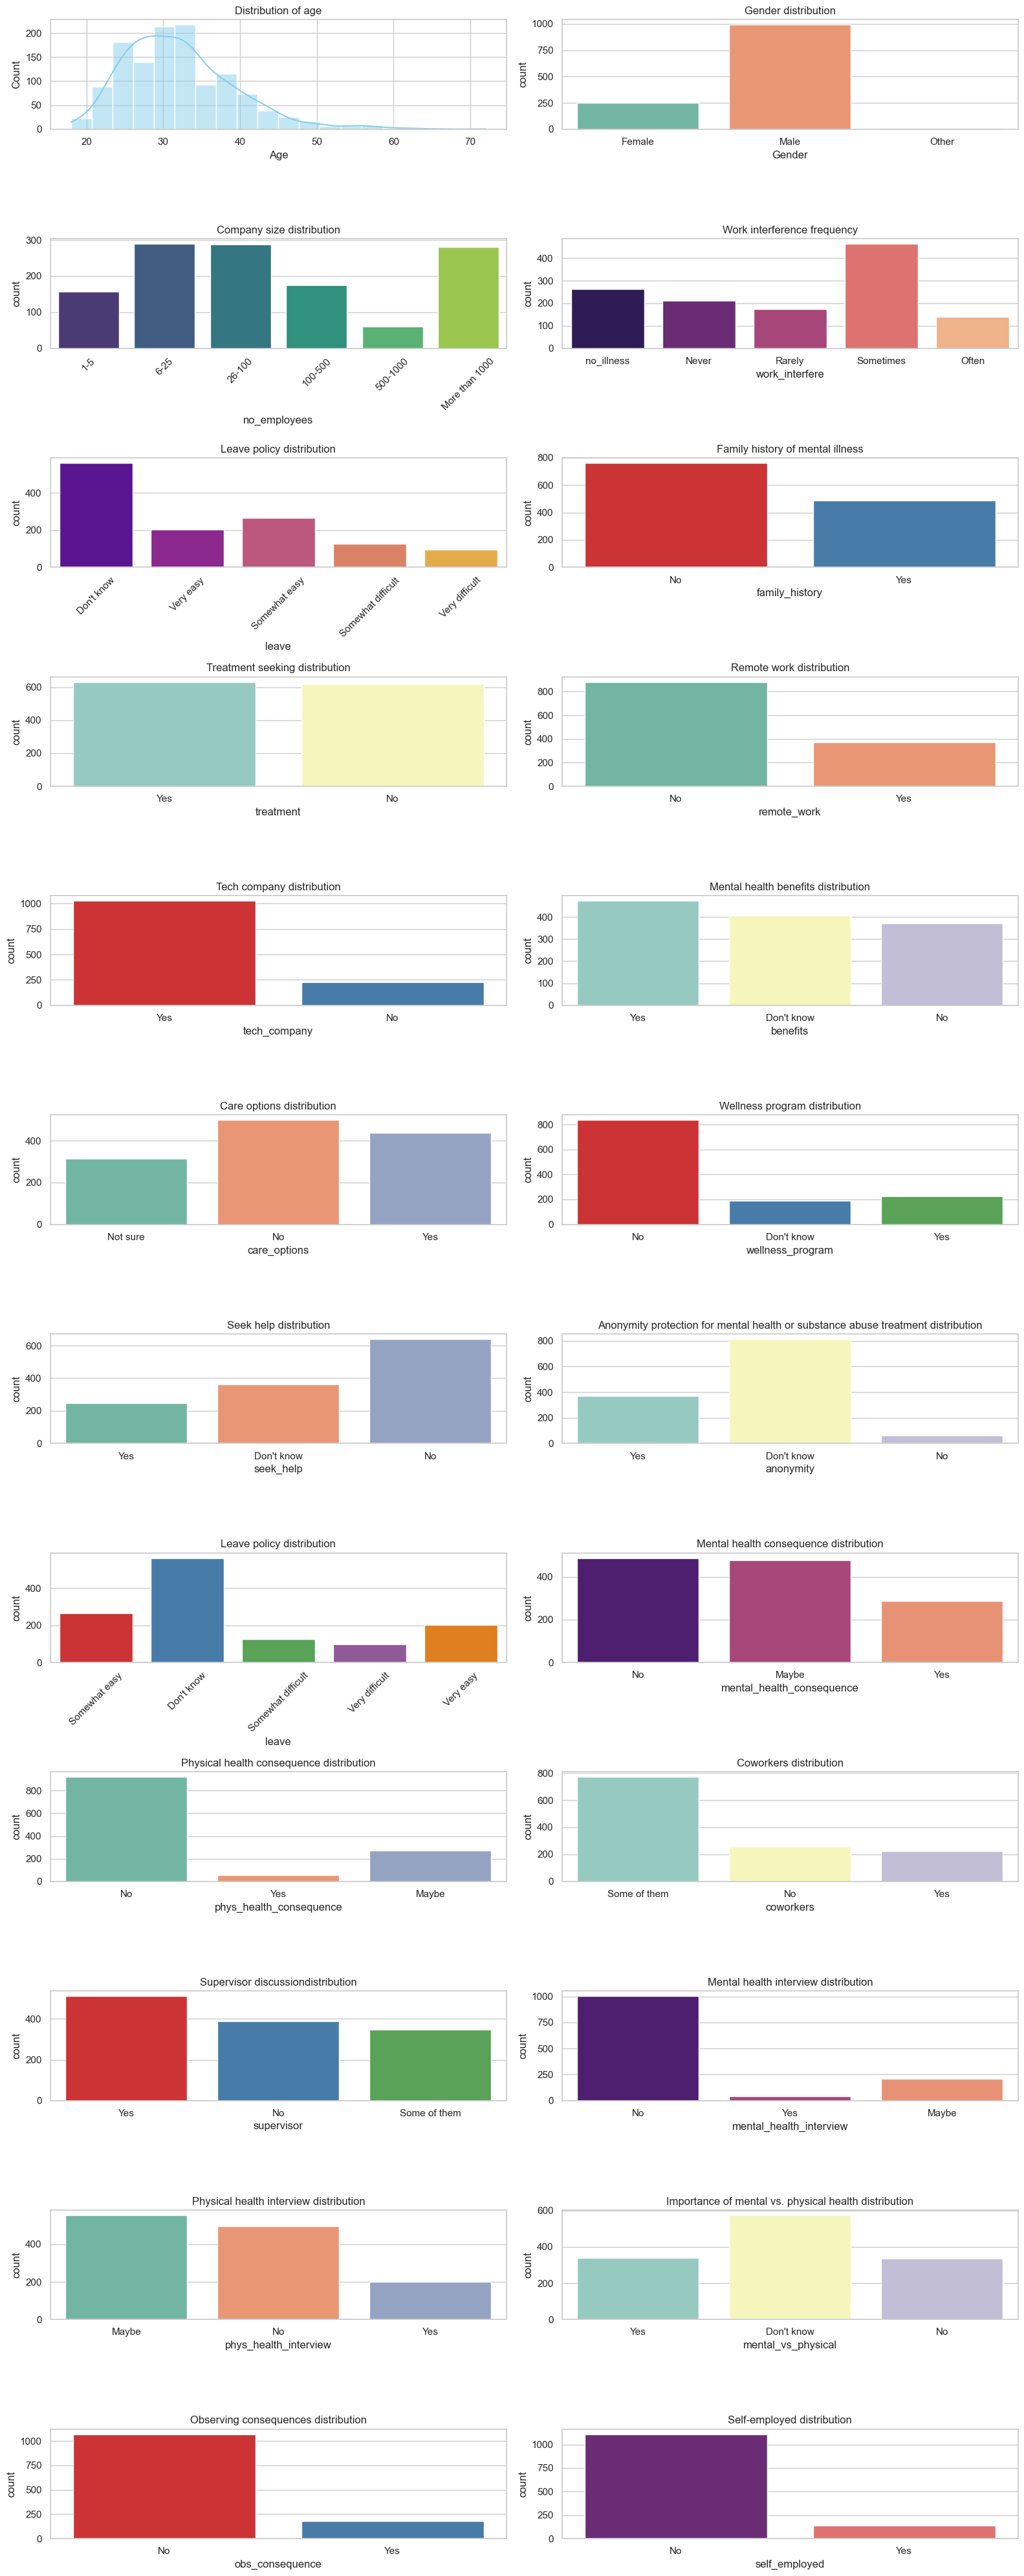

In [192]:
# EDA - exploratory data analysis for all genders and group ages

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(12, 2, figsize=(16, 40))

sns.histplot(data=df, x='Age', ax=axes[0, 0], color='skyblue', bins=20, kde=True)
axes[0, 0].set_title('Distribution of age')

sns.countplot(data=df, x='Gender', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Gender distribution')

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df, x='no_employees', order=size_order, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Company size distribution')
axes[1, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df, x='work_interfere', order=interfere_order, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Work interference frequency')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df, x='leave', order=leave_order, ax=axes[2, 0], palette='plasma')
axes[2, 0].set_title('Leave policy distribution')
axes[2, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='family_history', ax=axes[2, 1], palette='Set1')
axes[2, 1].set_title('Family history of mental illness')

sns.countplot(data=df, x='treatment', ax=axes[3, 0], palette='Set3')
axes[3, 0].set_title('Treatment seeking distribution')

sns.countplot(data=df, x='remote_work', ax=axes[3, 1], palette='Set2')
axes[3, 1].set_title('Remote work distribution')

sns.countplot(data=df, x='tech_company', ax=axes[4, 0], palette='Set1')
axes[4, 0].set_title('Tech company distribution')

sns.countplot(data=df, x='benefits', ax=axes[4, 1], palette='Set3')
axes[4, 1].set_title('Mental health benefits distribution')

sns.countplot(data=df, x='care_options', ax=axes[5, 0], palette='Set2')
axes[5, 0].set_title('Care options distribution')

sns.countplot(data=df, x='wellness_program', ax=axes[5, 1], palette='Set1')
axes[5, 1].set_title('Wellness program distribution')

sns.countplot(data=df, x='seek_help', ax=axes[6, 0], palette='Set2')
axes[6, 0].set_title('Seek help distribution')

sns.countplot(data=df, x='anonymity', ax=axes[6, 1], palette='Set3')
axes[6, 1].set_title('Anonymity protection for mental health or substance abuse treatment distribution')

sns.countplot(data=df, x='leave', ax=axes[7, 0], palette='Set1')
axes[7, 0].set_title('Leave policy distribution')
axes[7, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='mental_health_consequence',ax=axes[7, 1], palette='magma')
axes[7, 1].set_title('Mental health consequence distribution')

sns.countplot(data=df, x='phys_health_consequence', ax=axes[8, 0], palette='Set2')
axes[8, 0].set_title('Physical health consequence distribution')

sns.countplot(data=df, x='coworkers', ax=axes[8, 1], palette='Set3')
axes[8, 1].set_title('Coworkers distribution')

sns.countplot(data=df, x='supervisor', ax=axes[9, 0], palette='Set1')
axes[9, 0].set_title('Supervisor discussiondistribution')

sns.countplot(data=df, x='mental_health_interview', ax=axes[9, 1], palette='magma')
axes[9, 1].set_title('Mental health interview distribution')

sns.countplot(data=df, x='phys_health_interview', ax=axes[10, 0], palette='Set2')
axes[10, 0].set_title('Physical health interview distribution')

sns.countplot(data=df, x='mental_vs_physical', ax=axes[10, 1], palette='Set3')
axes[10, 1].set_title('Importance of mental vs. physical health distribution')

sns.countplot(data=df, x='obs_consequence', ax=axes[11, 0], palette='Set1')
axes[11, 0].set_title('Observing consequences distribution')

sns.countplot(data=df, x='self_employed', ax=axes[11, 1], palette='magma')
axes[11, 1].set_title('Self-employed distribution')

plt.tight_layout()
plt.show()

C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\925687338.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_US, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\925687338.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_US, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\925687338.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_US, x='leave', or

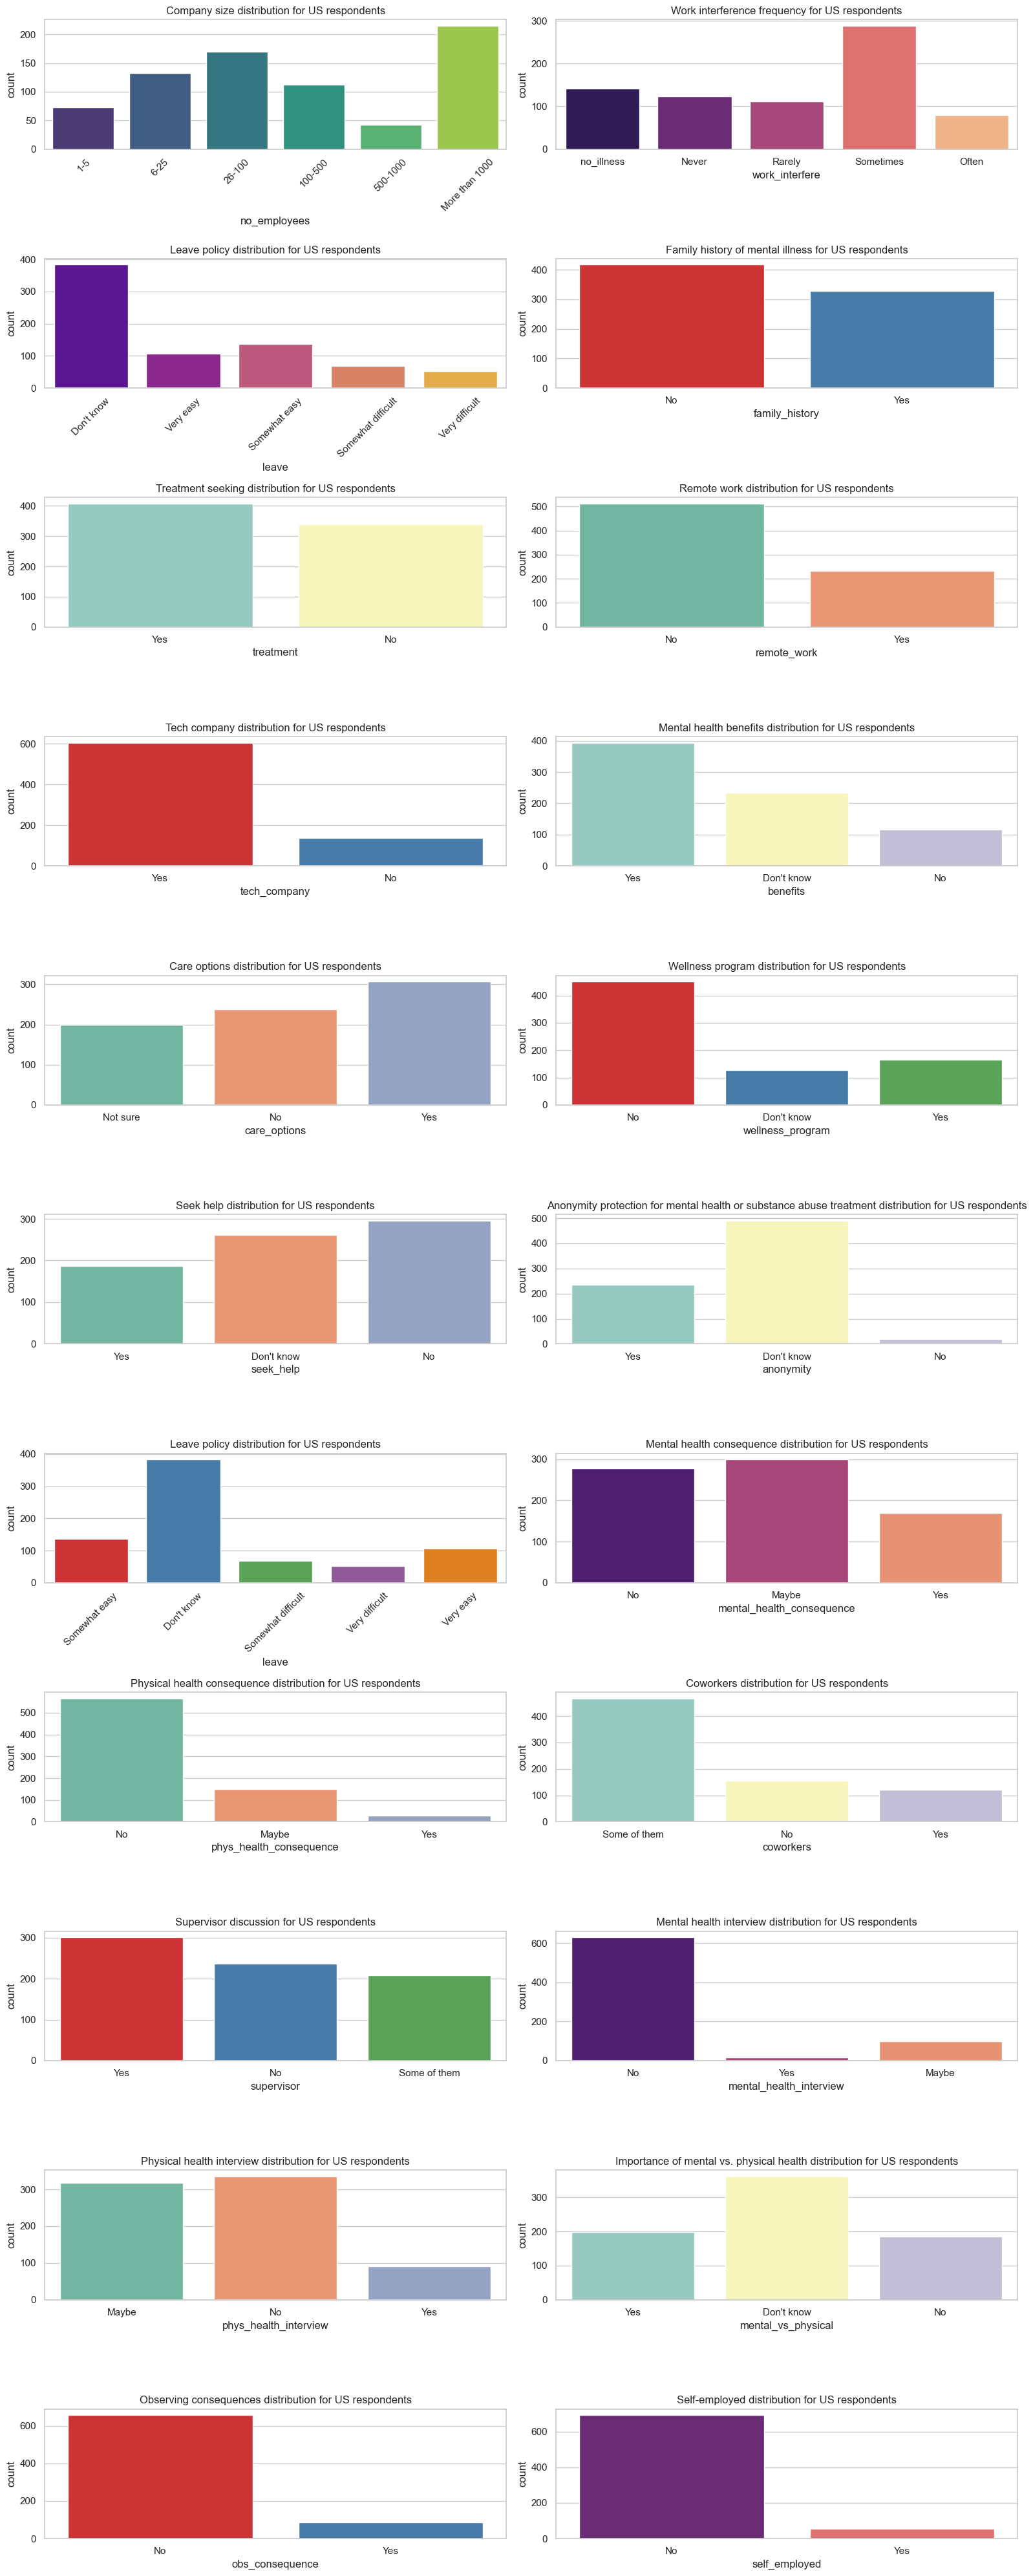

In [193]:
# EDA for US respondents

df_US = df[(df['Country'] == 'United States')].copy()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(11, 2, figsize=(16, 40))

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df_US, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Company size distribution for US respondents')
axes[0, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_US, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Work interference frequency for US respondents')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df_US, x='leave', order=leave_order, ax=axes[1, 0], palette='plasma')
axes[1, 0].set_title('Leave policy distribution for US respondents')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_US, x='family_history', ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Family history of mental illness for US respondents')

sns.countplot(data=df_US, x='treatment', ax=axes[2, 0], palette='Set3')
axes[2, 0].set_title('Treatment seeking distribution for US respondents')

sns.countplot(data=df_US, x='remote_work', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Remote work distribution for US respondents')

sns.countplot(data=df_US, x='tech_company', ax=axes[3, 0], palette='Set1')
axes[3, 0].set_title('Tech company distribution for US respondents')

sns.countplot(data=df_US, x='benefits', ax=axes[3, 1], palette='Set3')
axes[3, 1].set_title('Mental health benefits distribution for US respondents')

sns.countplot(data=df_US, x='care_options', ax=axes[4, 0], palette='Set2')
axes[4, 0].set_title('Care options distribution for US respondents')

sns.countplot(data=df_US, x='wellness_program', ax=axes[4, 1], palette='Set1')
axes[4, 1].set_title('Wellness program distribution for US respondents')

sns.countplot(data=df_US, x='seek_help', ax=axes[5, 0], palette='Set2')
axes[5, 0].set_title('Seek help distribution for US respondents')

sns.countplot(data=df_US, x='anonymity', ax=axes[5, 1], palette='Set3')
axes[5, 1].set_title('Anonymity protection for mental health or substance abuse treatment distribution for US respondents')

sns.countplot(data=df_US, x='leave', ax=axes[6, 0], palette='Set1')
axes[6, 0].set_title('Leave policy distribution for US respondents')
axes[6, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_US, x='mental_health_consequence',ax=axes[6, 1], palette='magma')
axes[6, 1].set_title('Mental health consequence distribution for US respondents')

sns.countplot(data=df_US, x='phys_health_consequence', ax=axes[7, 0], palette='Set2')
axes[7, 0].set_title('Physical health consequence distribution for US respondents')

sns.countplot(data=df_US, x='coworkers', ax=axes[7, 1], palette='Set3')
axes[7, 1].set_title('Coworkers distribution for US respondents')

sns.countplot(data=df_US, x='supervisor', ax=axes[8, 0], palette='Set1')
axes[8, 0].set_title('Supervisor discussion for US respondents')

sns.countplot(data=df_US, x='mental_health_interview', ax=axes[8, 1], palette='magma')
axes[8, 1].set_title('Mental health interview distribution for US respondents')

sns.countplot(data=df_US, x='phys_health_interview', ax=axes[9, 0], palette='Set2')
axes[9, 0].set_title('Physical health interview distribution for US respondents')

sns.countplot(data=df_US, x='mental_vs_physical', ax=axes[9, 1], palette='Set3')
axes[9, 1].set_title('Importance of mental vs. physical health distribution for US respondents')

sns.countplot(data=df_US, x='obs_consequence', ax=axes[10, 0], palette='Set1')
axes[10, 0].set_title('Observing consequences distribution for US respondents')

sns.countplot(data=df_US, x='self_employed', ax=axes[10, 1], palette='magma')
axes[10, 1].set_title('Self-employed distribution for US respondents')

plt.tight_layout()
plt.show()

C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\35964094.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_young, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\35964094.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_young, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\35964094.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_young, x='lea

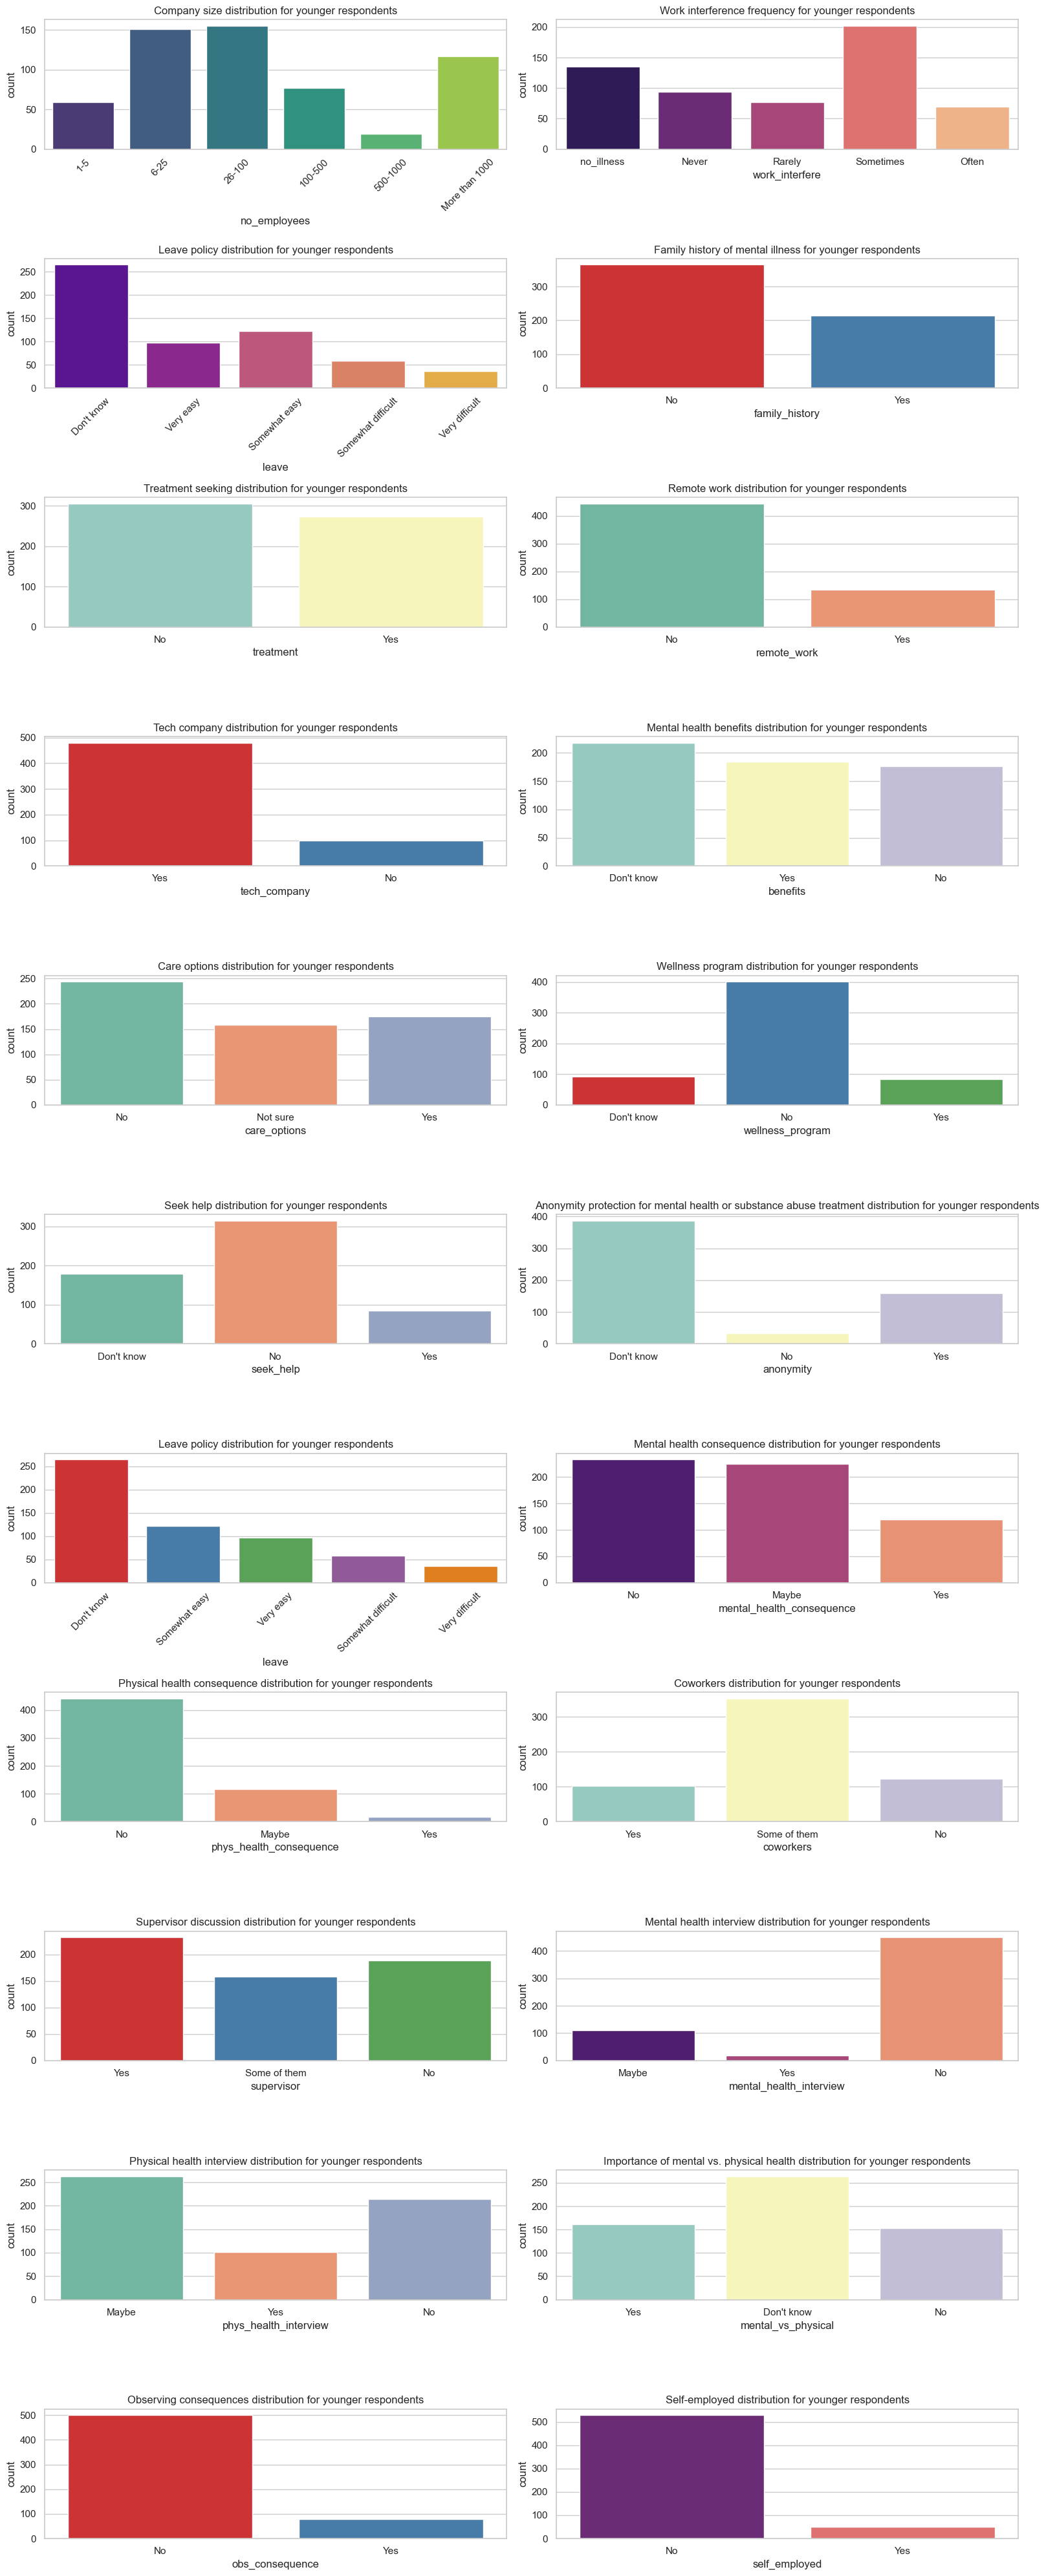

In [194]:
# EDA for younger half of data set

median_age = df['Age'].median()
df_young = df[df['Age'] < median_age].copy()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(11, 2, figsize=(16, 40))

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df_young, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Company size distribution for younger respondents')
axes[0, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_young, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Work interference frequency for younger respondents')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df_young, x='leave', order=leave_order, ax=axes[1, 0], palette='plasma')
axes[1, 0].set_title('Leave policy distribution for younger respondents')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_young, x='family_history', ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Family history of mental illness for younger respondents')

sns.countplot(data=df_young, x='treatment', ax=axes[2, 0], palette='Set3')
axes[2, 0].set_title('Treatment seeking distribution for younger respondents')

sns.countplot(data=df_young, x='remote_work', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Remote work distribution for younger respondents')

sns.countplot(data=df_young, x='tech_company', ax=axes[3, 0], palette='Set1')
axes[3, 0].set_title('Tech company distribution for younger respondents')

sns.countplot(data=df_young, x='benefits', ax=axes[3, 1], palette='Set3')
axes[3, 1].set_title('Mental health benefits distribution for younger respondents')

sns.countplot(data=df_young, x='care_options', ax=axes[4, 0], palette='Set2')
axes[4, 0].set_title('Care options distribution for younger respondents')

sns.countplot(data=df_young, x='wellness_program', ax=axes[4, 1], palette='Set1')
axes[4, 1].set_title('Wellness program distribution for younger respondents')

sns.countplot(data=df_young, x='seek_help', ax=axes[5, 0], palette='Set2')
axes[5, 0].set_title('Seek help distribution for younger respondents')

sns.countplot(data=df_young, x='anonymity', ax=axes[5, 1], palette='Set3')
axes[5, 1].set_title('Anonymity protection for mental health or substance abuse treatment distribution for younger respondents')

sns.countplot(data=df_young, x='leave', ax=axes[6, 0], palette='Set1')
axes[6, 0].set_title('Leave policy distribution for younger respondents')
axes[6, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_young, x='mental_health_consequence',ax=axes[6, 1], palette='magma')
axes[6, 1].set_title('Mental health consequence distribution for younger respondents')

sns.countplot(data=df_young, x='phys_health_consequence', ax=axes[7, 0], palette='Set2')
axes[7, 0].set_title('Physical health consequence distribution for younger respondents')

sns.countplot(data=df_young, x='coworkers', ax=axes[7, 1], palette='Set3')
axes[7, 1].set_title('Coworkers distribution for younger respondents')

sns.countplot(data=df_young, x='supervisor', ax=axes[8, 0], palette='Set1')
axes[8, 0].set_title('Supervisor discussion distribution for younger respondents')

sns.countplot(data=df_young, x='mental_health_interview', ax=axes[8, 1], palette='magma')
axes[8, 1].set_title('Mental health interview distribution for younger respondents')

sns.countplot(data=df_young, x='phys_health_interview', ax=axes[9, 0], palette='Set2')
axes[9, 0].set_title('Physical health interview distribution for younger respondents')

sns.countplot(data=df_young, x='mental_vs_physical', ax=axes[9, 1], palette='Set3')
axes[9, 1].set_title('Importance of mental vs. physical health distribution for younger respondents')

sns.countplot(data=df_young, x='obs_consequence', ax=axes[10, 0], palette='Set1')
axes[10, 0].set_title('Observing consequences distribution for younger respondents')

sns.countplot(data=df_young, x='self_employed', ax=axes[10, 1], palette='magma')
axes[10, 1].set_title('Self-employed distribution for younger respondents')

plt.tight_layout()
plt.show()


C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\2343011364.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_old, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\2343011364.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_old, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\2343011364.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_old, x='leav

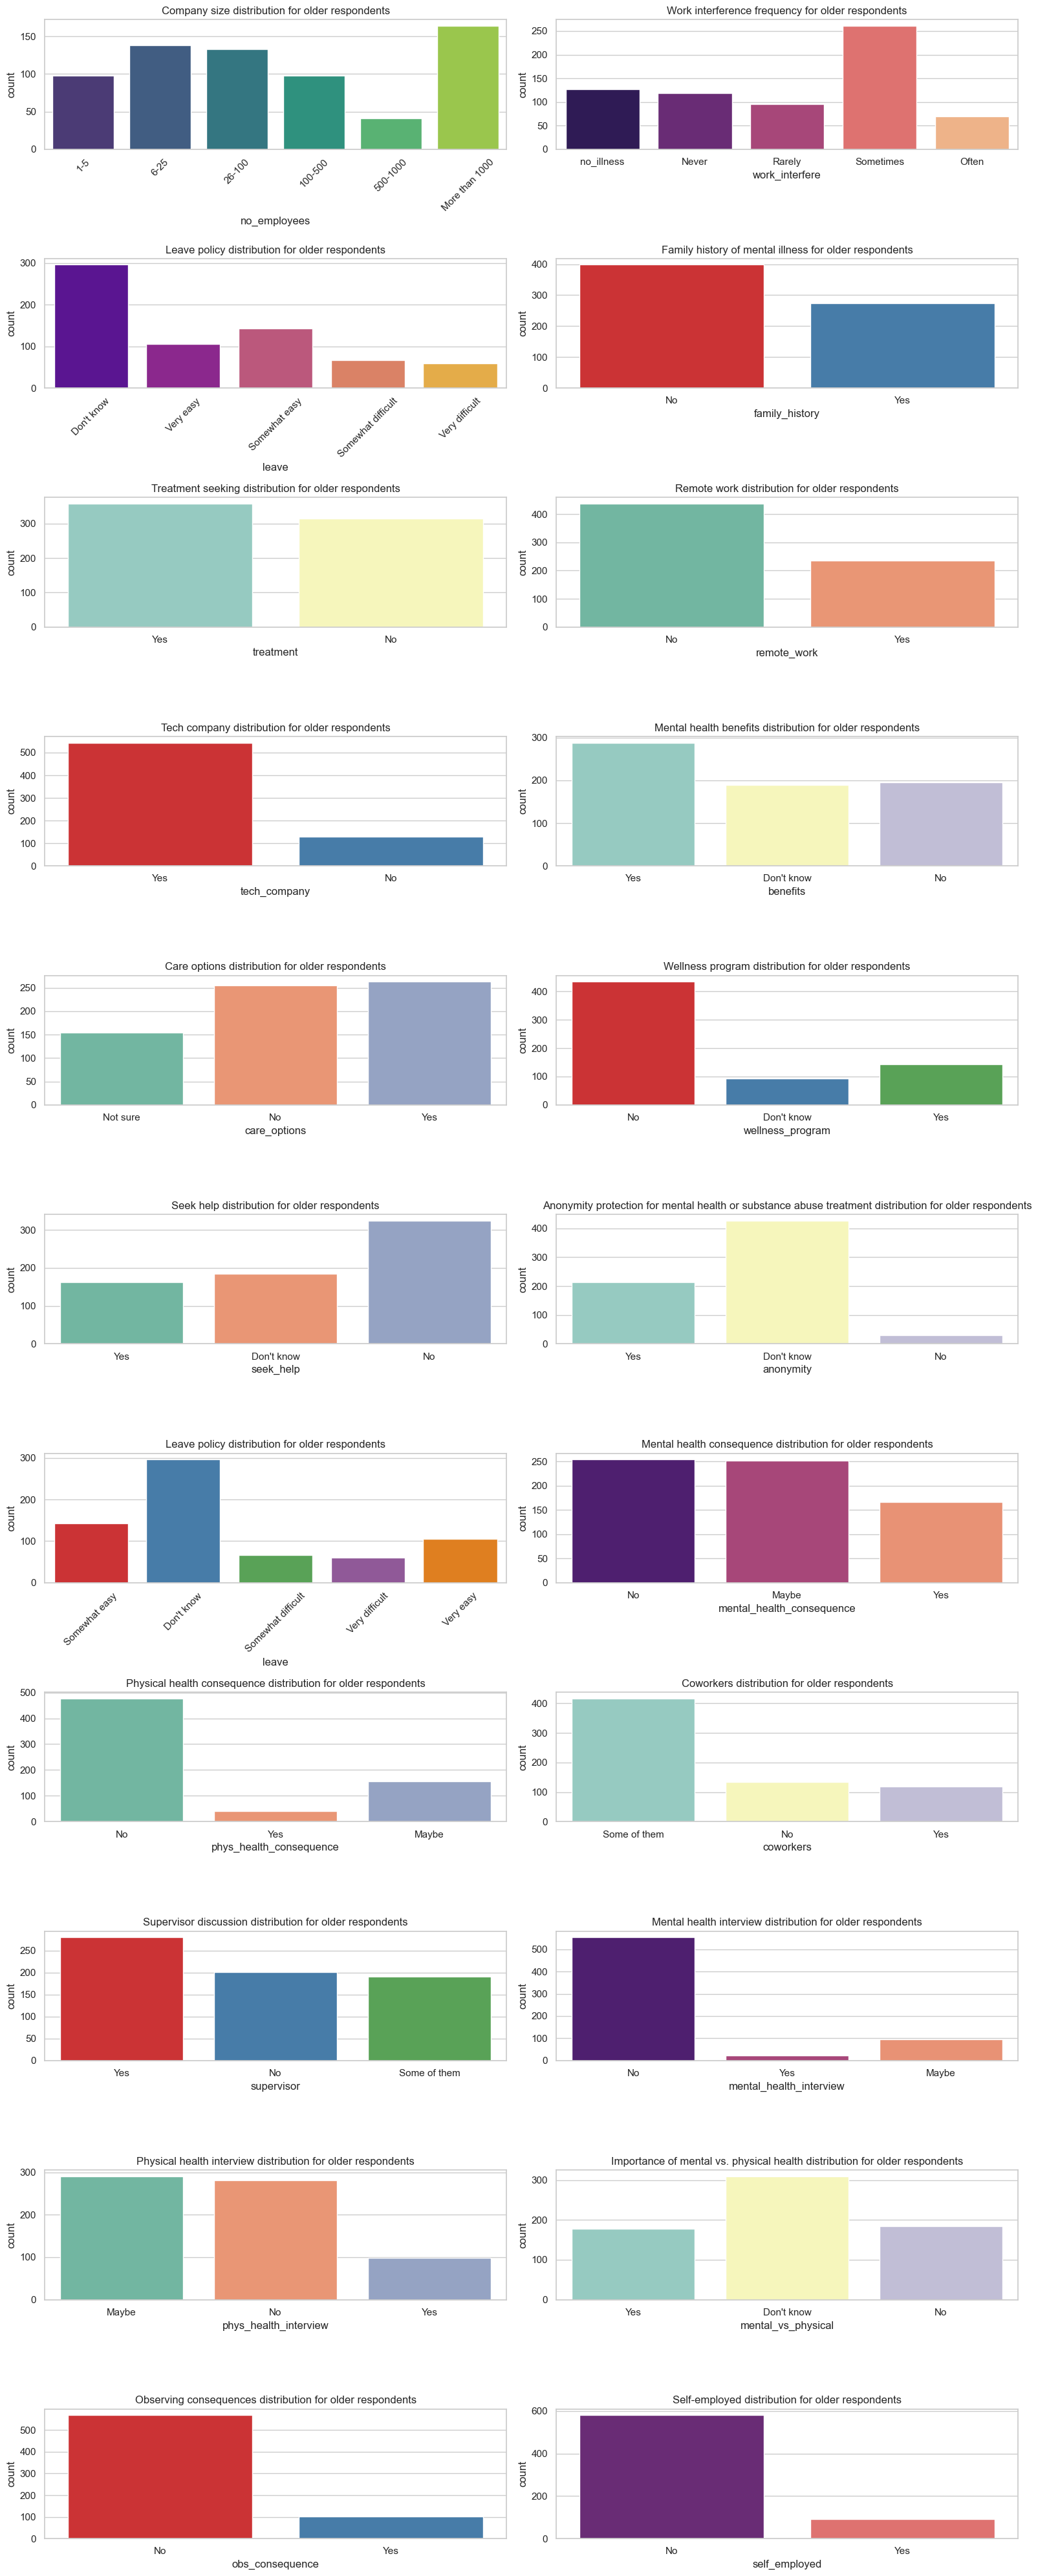

In [195]:
# EDA for older half of data set

df_old = df[df['Age'] >= median_age].copy()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(11, 2, figsize=(16, 40))

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df_old, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Company size distribution for older respondents')
axes[0, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_old, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Work interference frequency for older respondents')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df_old, x='leave', order=leave_order, ax=axes[1, 0], palette='plasma')
axes[1, 0].set_title('Leave policy distribution for older respondents')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_old, x='family_history', ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Family history of mental illness for older respondents')

sns.countplot(data=df_old, x='treatment', ax=axes[2, 0], palette='Set3')
axes[2, 0].set_title('Treatment seeking distribution for older respondents')

sns.countplot(data=df_old, x='remote_work', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Remote work distribution for older respondents')

sns.countplot(data=df_old, x='tech_company', ax=axes[3, 0], palette='Set1')
axes[3, 0].set_title('Tech company distribution for older respondents')

sns.countplot(data=df_old, x='benefits', ax=axes[3, 1], palette='Set3')
axes[3, 1].set_title('Mental health benefits distribution for older respondents')

sns.countplot(data=df_old, x='care_options', ax=axes[4, 0], palette='Set2')
axes[4, 0].set_title('Care options distribution for older respondents')

sns.countplot(data=df_old, x='wellness_program', ax=axes[4, 1], palette='Set1')
axes[4, 1].set_title('Wellness program distribution for older respondents')

sns.countplot(data=df_old, x='seek_help', ax=axes[5, 0], palette='Set2')
axes[5, 0].set_title('Seek help distribution for older respondents')

sns.countplot(data=df_old, x='anonymity', ax=axes[5, 1], palette='Set3')
axes[5, 1].set_title('Anonymity protection for mental health or substance abuse treatment distribution for older respondents')

sns.countplot(data=df_old, x='leave', ax=axes[6, 0], palette='Set1')
axes[6, 0].set_title('Leave policy distribution for older respondents')
axes[6, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_old, x='mental_health_consequence',ax=axes[6, 1], palette='magma')
axes[6, 1].set_title('Mental health consequence distribution for older respondents')

sns.countplot(data=df_old, x='phys_health_consequence', ax=axes[7, 0], palette='Set2')
axes[7, 0].set_title('Physical health consequence distribution for older respondents')

sns.countplot(data=df_old, x='coworkers', ax=axes[7, 1], palette='Set3')
axes[7, 1].set_title('Coworkers distribution for older respondents')

sns.countplot(data=df_old, x='supervisor', ax=axes[8, 0], palette='Set1')
axes[8, 0].set_title('Supervisor discussion distribution for older respondents')

sns.countplot(data=df_old, x='mental_health_interview', ax=axes[8, 1], palette='magma')
axes[8, 1].set_title('Mental health interview distribution for older respondents')

sns.countplot(data=df_old, x='phys_health_interview', ax=axes[9, 0], palette='Set2')
axes[9, 0].set_title('Physical health interview distribution for older respondents')

sns.countplot(data=df_old, x='mental_vs_physical', ax=axes[9, 1], palette='Set3')
axes[9, 1].set_title('Importance of mental vs. physical health distribution for older respondents')

sns.countplot(data=df_old, x='obs_consequence', ax=axes[10, 0], palette='Set1')
axes[10, 0].set_title('Observing consequences distribution for older respondents')

sns.countplot(data=df_old, x='self_employed', ax=axes[10, 1], palette='magma')
axes[10, 1].set_title('Self-employed distribution for older respondents')

plt.tight_layout()
plt.show()

C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\2517754539.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_females, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\2517754539.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_females, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\2517754539.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_fema

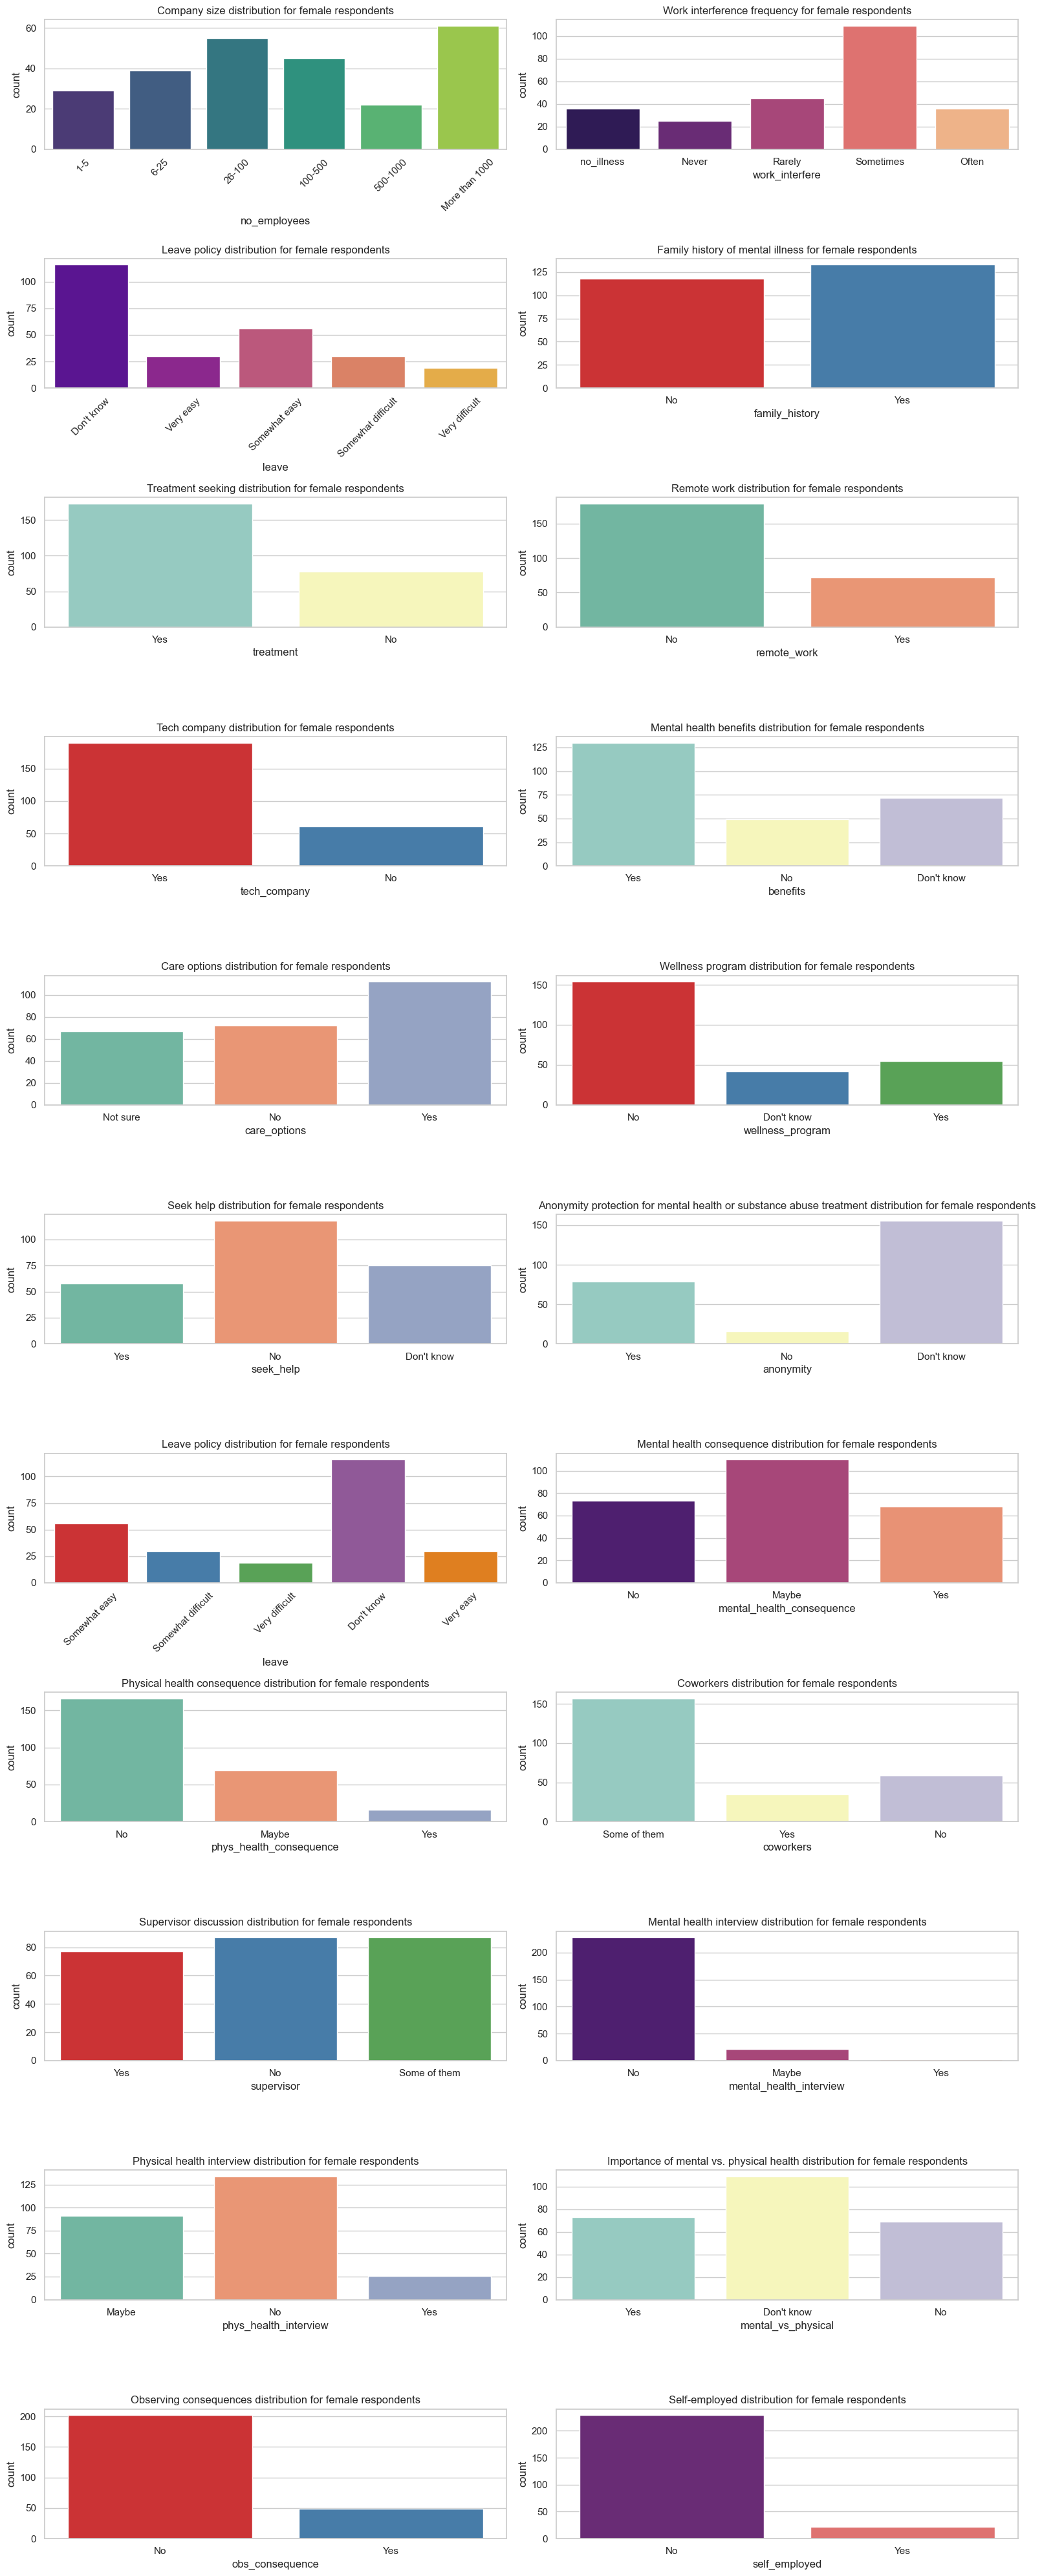

In [196]:
# EDA for females

df_females = df[df['Gender'] == 'Female'].copy()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(11, 2, figsize=(16, 40))

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df_females, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Company size distribution for female respondents')
axes[0, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_females, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Work interference frequency for female respondents')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df_females, x='leave', order=leave_order, ax=axes[1, 0], palette='plasma')
axes[1, 0].set_title('Leave policy distribution for female respondents')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_females, x='family_history', ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Family history of mental illness for female respondents')

sns.countplot(data=df_females, x='treatment', ax=axes[2, 0], palette='Set3')
axes[2, 0].set_title('Treatment seeking distribution for female respondents')

sns.countplot(data=df_females, x='remote_work', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Remote work distribution for female respondents')

sns.countplot(data=df_females, x='tech_company', ax=axes[3, 0], palette='Set1')
axes[3, 0].set_title('Tech company distribution for female respondents')

sns.countplot(data=df_females, x='benefits', ax=axes[3, 1], palette='Set3')
axes[3, 1].set_title('Mental health benefits distribution for female respondents')

sns.countplot(data=df_females, x='care_options', ax=axes[4, 0], palette='Set2')
axes[4, 0].set_title('Care options distribution for female respondents')

sns.countplot(data=df_females, x='wellness_program', ax=axes[4, 1], palette='Set1')
axes[4, 1].set_title('Wellness program distribution for female respondents')

sns.countplot(data=df_females, x='seek_help', ax=axes[5, 0], palette='Set2')
axes[5, 0].set_title('Seek help distribution for female respondents')

sns.countplot(data=df_females, x='anonymity', ax=axes[5, 1], palette='Set3')
axes[5, 1].set_title('Anonymity protection for mental health or substance abuse treatment distribution for female respondents')

sns.countplot(data=df_females, x='leave', ax=axes[6, 0], palette='Set1')
axes[6, 0].set_title('Leave policy distribution for female respondents')
axes[6, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_females, x='mental_health_consequence',ax=axes[6, 1], palette='magma')
axes[6, 1].set_title('Mental health consequence distribution for female respondents')

sns.countplot(data=df_females, x='phys_health_consequence', ax=axes[7, 0], palette='Set2')
axes[7, 0].set_title('Physical health consequence distribution for female respondents')

sns.countplot(data=df_females, x='coworkers', ax=axes[7, 1], palette='Set3')
axes[7, 1].set_title('Coworkers distribution for female respondents')

sns.countplot(data=df_females, x='supervisor', ax=axes[8, 0], palette='Set1')
axes[8, 0].set_title('Supervisor discussion distribution for female respondents')

sns.countplot(data=df_females, x='mental_health_interview', ax=axes[8, 1], palette='magma')
axes[8, 1].set_title('Mental health interview distribution for female respondents')

sns.countplot(data=df_females, x='phys_health_interview', ax=axes[9, 0], palette='Set2')
axes[9, 0].set_title('Physical health interview distribution for female respondents')

sns.countplot(data=df_females, x='mental_vs_physical', ax=axes[9, 1], palette='Set3')
axes[9, 1].set_title('Importance of mental vs. physical health distribution for female respondents')

sns.countplot(data=df_females, x='obs_consequence', ax=axes[10, 0], palette='Set1')
axes[10, 0].set_title('Observing consequences distribution for female respondents')

sns.countplot(data=df_females, x='self_employed', ax=axes[10, 1], palette='magma')
axes[10, 1].set_title('Self-employed distribution for female respondents')

plt.tight_layout()
plt.show()

C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\819751044.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_males, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\819751044.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_males, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_12524\819751044.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_males, x='l

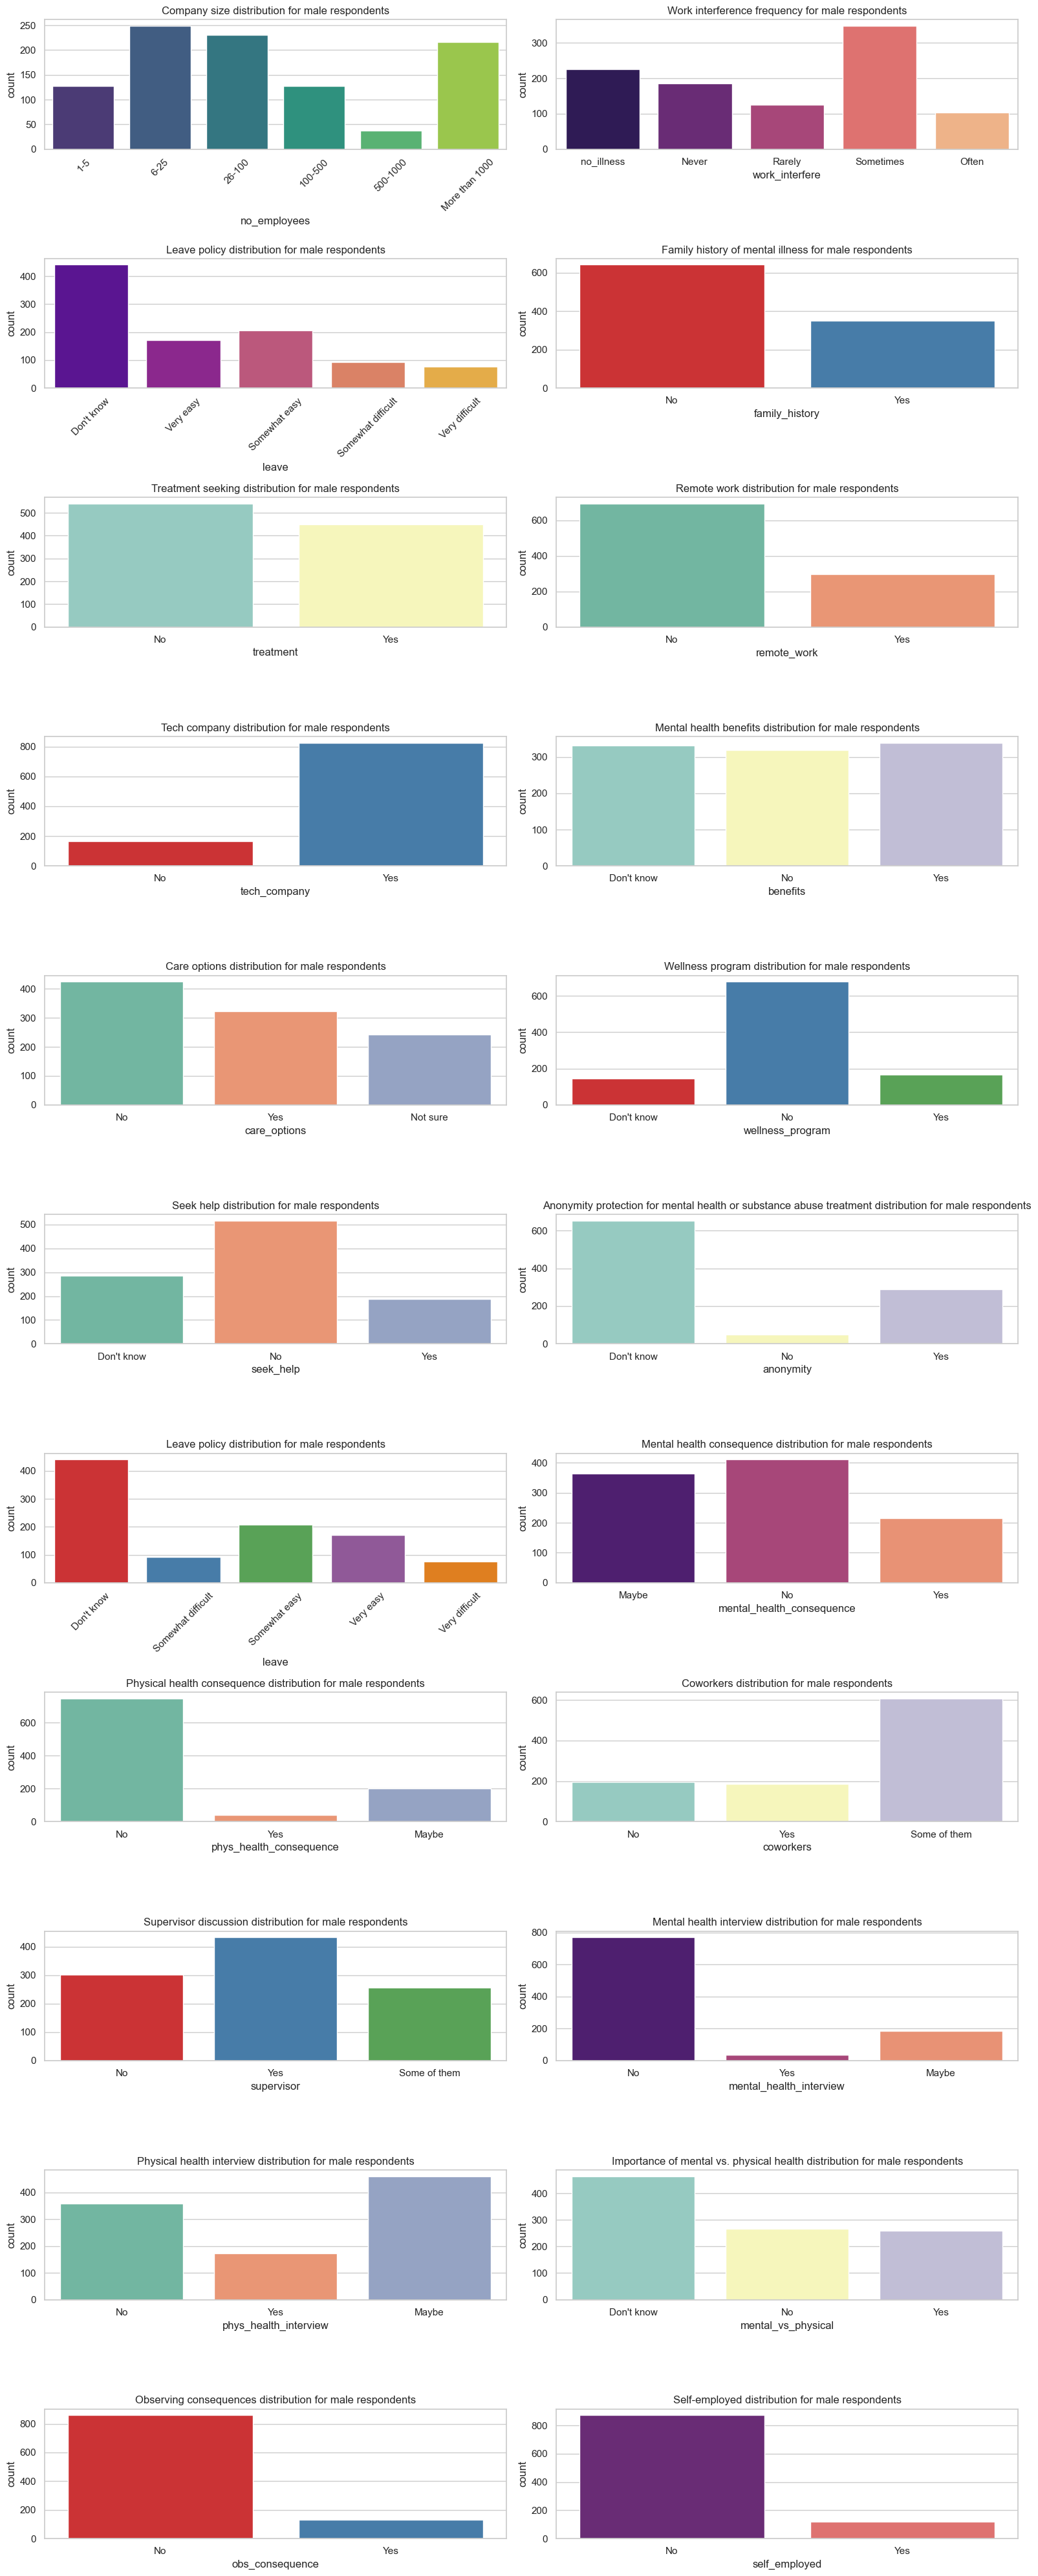

In [197]:
# EDA for males

df_males = df[df['Gender'] == 'Male'].copy()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(11, 2, figsize=(16, 40))

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df_males, x='no_employees', order=size_order, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Company size distribution for male respondents')
axes[0, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_males, x='work_interfere', order=interfere_order, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Work interference frequency for male respondents')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df_males, x='leave', order=leave_order, ax=axes[1, 0], palette='plasma')
axes[1, 0].set_title('Leave policy distribution for male respondents')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_males, x='family_history', ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Family history of mental illness for male respondents')

sns.countplot(data=df_males, x='treatment', ax=axes[2, 0], palette='Set3')
axes[2, 0].set_title('Treatment seeking distribution for male respondents')

sns.countplot(data=df_males, x='remote_work', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Remote work distribution for male respondents')

sns.countplot(data=df_males, x='tech_company', ax=axes[3, 0], palette='Set1')
axes[3, 0].set_title('Tech company distribution for male respondents')

sns.countplot(data=df_males, x='benefits', ax=axes[3, 1], palette='Set3')
axes[3, 1].set_title('Mental health benefits distribution for male respondents')

sns.countplot(data=df_males, x='care_options', ax=axes[4, 0], palette='Set2')
axes[4, 0].set_title('Care options distribution for male respondents')

sns.countplot(data=df_males, x='wellness_program', ax=axes[4, 1], palette='Set1')
axes[4, 1].set_title('Wellness program distribution for male respondents')

sns.countplot(data=df_males, x='seek_help', ax=axes[5, 0], palette='Set2')
axes[5, 0].set_title('Seek help distribution for male respondents')

sns.countplot(data=df_males, x='anonymity', ax=axes[5, 1], palette='Set3')
axes[5, 1].set_title('Anonymity protection for mental health or substance abuse treatment distribution for male respondents')

sns.countplot(data=df_males, x='leave', ax=axes[6, 0], palette='Set1')
axes[6, 0].set_title('Leave policy distribution for male respondents')
axes[6, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_males, x='mental_health_consequence',ax=axes[6, 1], palette='magma')
axes[6, 1].set_title('Mental health consequence distribution for male respondents')

sns.countplot(data=df_males, x='phys_health_consequence', ax=axes[7, 0], palette='Set2')
axes[7, 0].set_title('Physical health consequence distribution for male respondents')

sns.countplot(data=df_males, x='coworkers', ax=axes[7, 1], palette='Set3')
axes[7, 1].set_title('Coworkers distribution for male respondents')

sns.countplot(data=df_males, x='supervisor', ax=axes[8, 0], palette='Set1')
axes[8, 0].set_title('Supervisor discussion distribution for male respondents')

sns.countplot(data=df_males, x='mental_health_interview', ax=axes[8, 1], palette='magma')
axes[8, 1].set_title('Mental health interview distribution for male respondents')

sns.countplot(data=df_males, x='phys_health_interview', ax=axes[9, 0], palette='Set2')
axes[9, 0].set_title('Physical health interview distribution for male respondents')

sns.countplot(data=df_males, x='mental_vs_physical', ax=axes[9, 1], palette='Set3')
axes[9, 1].set_title('Importance of mental vs. physical health distribution for male respondents')

sns.countplot(data=df_males, x='obs_consequence', ax=axes[10, 0], palette='Set1')
axes[10, 0].set_title('Observing consequences distribution for male respondents')

sns.countplot(data=df_males, x='self_employed', ax=axes[10, 1], palette='magma')
axes[10, 1].set_title('Self-employed distribution for male respondents')

plt.tight_layout()
plt.show()

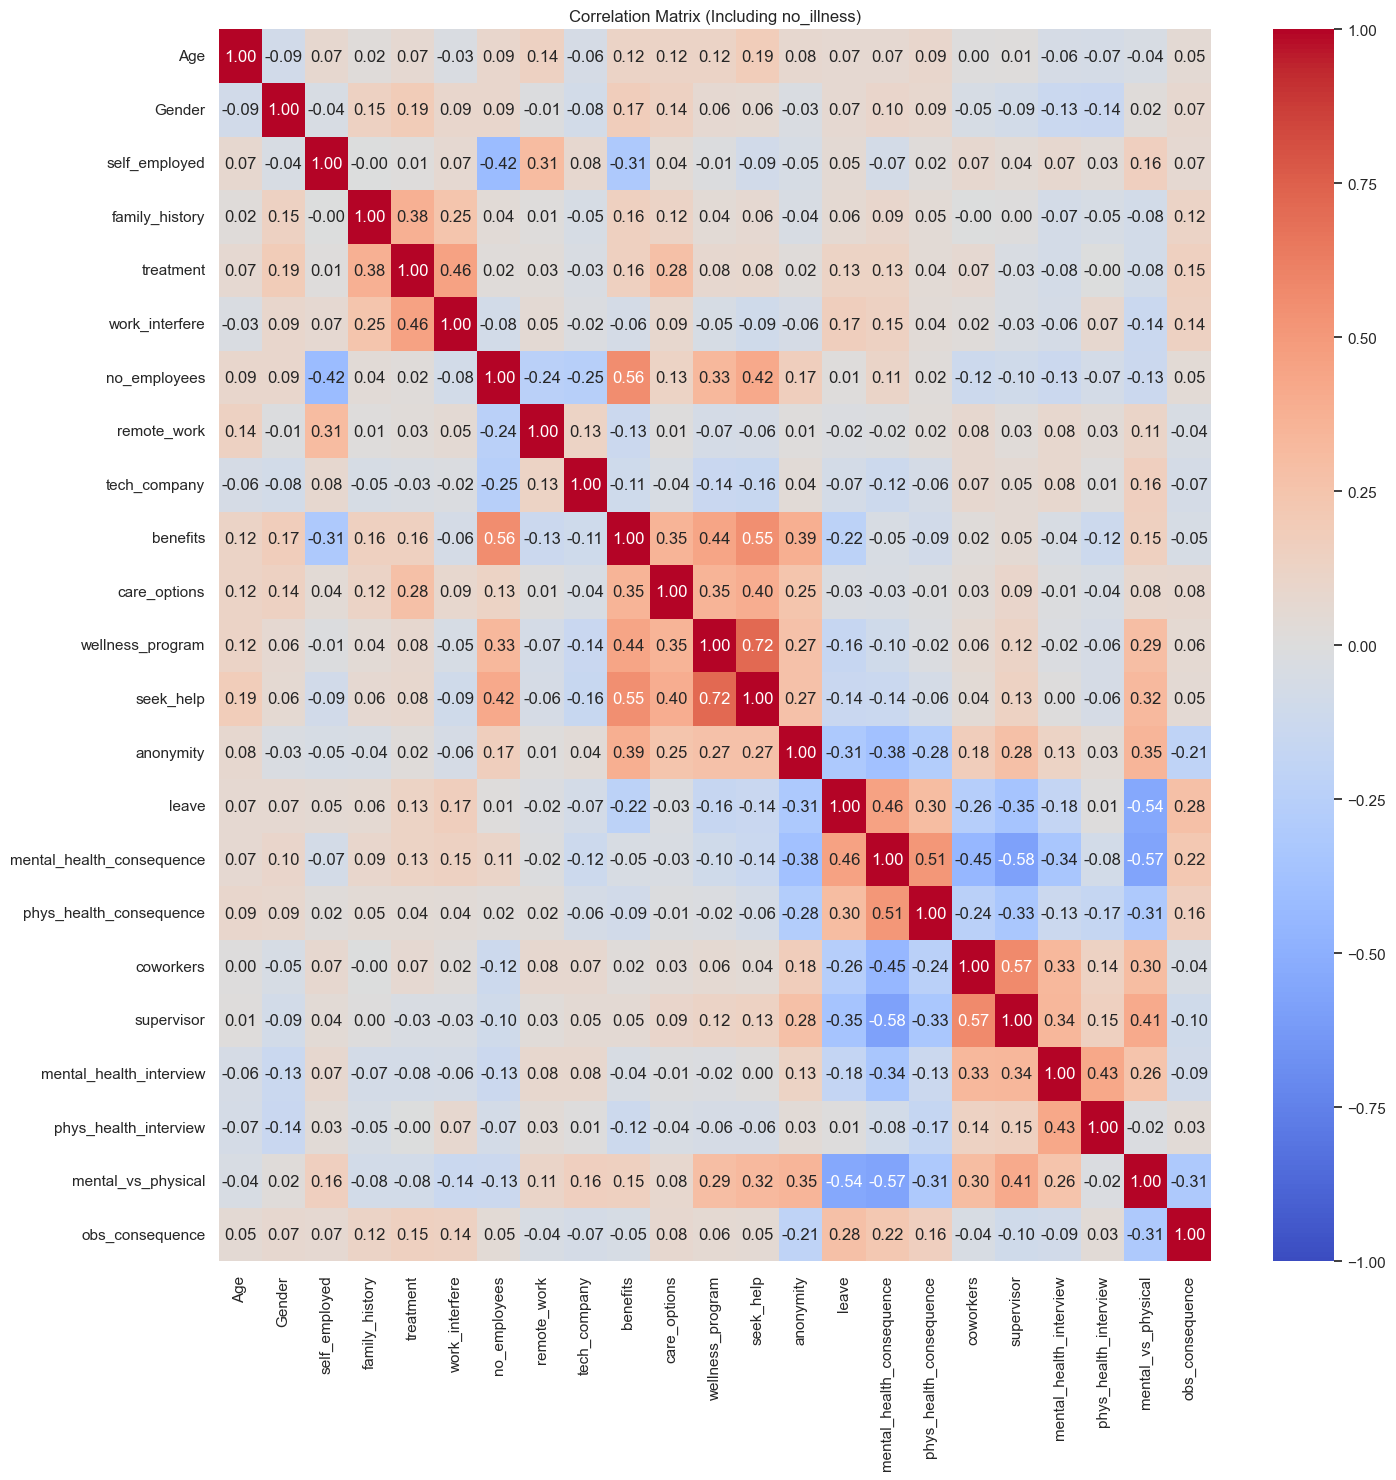

In [198]:
# CORRELATIONS BETWEEN ATTRIBUTES for all genders and group ages
df_encoded = df.copy()

# binary encoding (variables with Yes/No values, samples with Don't know values and with Not sure values were left out of this encoding due to their ambiguity)
binary_cols = ['family_history', 'treatment', 'self_employed', 'remote_work', 'tech_company', 'benefits', 'care_options', 'wellness_program', 'seek_help', 'anonymity', 'mental_vs_physical', 'obs_consequence']
for col in binary_cols:
    if col in df_encoded.columns:
        df_encoded[col] = df_encoded[col].map({'Yes': 1, 'No': 0})

# binary encoding for gender column
if 'Gender' in df_encoded.columns:
    # 'Other' category is left out of this encoding due to its small sample size and possible disruption of the results depending on number assigned
    df_encoded['Gender'] = df_encoded['Gender'].map({'Male': 0, 'Female': 1})

# ordinal encoding with Maybe/Somewhat/Some of them as 1, Yes as 2 and No as 0
ordinal_cols = ['mental_health_consequence', 'phys_health_consequence', 'coworkers', 'supervisor', 'mental_health_interview', 'phys_health_interview']
for col in ordinal_cols:
    if col in df_encoded.columns:
        df_encoded[col] = df_encoded[col].map({'Yes': 2, 'Maybe': 1, 'Somewhat': 1, 'Some of them': 1, 'No': 0})

# ordinal encoding for work_interfere (0 = Never, 4 = often)
if 'work_interfere' in df_encoded.columns:
    interfere_map = {'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Often': 3}
    df_encoded['work_interfere'] = df_encoded['work_interfere'].map(interfere_map)

# ordinal encoding for no_employees (0 = 1-5, 5 = More than 1000)
if 'no_employees' in df_encoded.columns:
    employees_map = {'1-5': 0, '6-25': 1, '26-100': 2, '100-500': 3, '500-1000': 4, 'More than 1000': 5}
    df_encoded['no_employees'] = df_encoded['no_employees'].map(employees_map)

# ordinal encoding for leave (0 = Very easy, 4 = Very difficult)
if 'leave' in df_encoded.columns:
    leave_map = {'Very easy': 0, 'Somewhat easy': 1, 'Somewhat difficult': 2, 'Very difficult': 3}
    df_encoded['leave'] = df_encoded['leave'].map(leave_map)

# heatmap of correlations between attributes using Spearman's rank correlation coefficient, which is appropriate for ordinal and binary data
# Country and state columns are left out of the correlation calculation since they are categorical variables with many unique values
# NaN values (ambiguous answers like "Don't know" or no_illness category, created from originally NaN values, in work_interference)
# are not included in the correlation calculation since they are considered to be outside of the scale,
# pandas .corr() function automatically excludes them from the correlation calculation, so no additional handling is needed for these values in this context
plt.figure(figsize=(16, 16))
numeric_df = df_encoded.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix (Including no_illness)')
plt.show()

In [199]:
# dataset preparation for modeling

# rows with NaN values must be supplemented with -1 to represent separate category
# if we were to drop rows with NaN values, we would lose a significant portion of the data
df_model = numeric_df.fillna(-1)

target = 'treatment'
X = df_model.drop(target, axis=1)
y = df_model[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data size: {len(X_train)}")
print(f"Test data size: {len(X_test)}")

Training data size: 1000
Test data size: 250


Accuracy: 0.8360


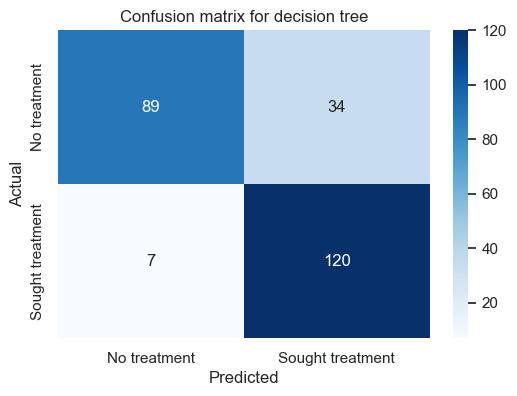

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.72      0.81       123
           1       0.78      0.94      0.85       127

    accuracy                           0.84       250
   macro avg       0.85      0.83      0.83       250
weighted avg       0.85      0.84      0.83       250


Top 7 most important features:
['work_interfere', 'family_history', 'benefits', 'anonymity', 'Age', 'care_options', 'obs_consequence']


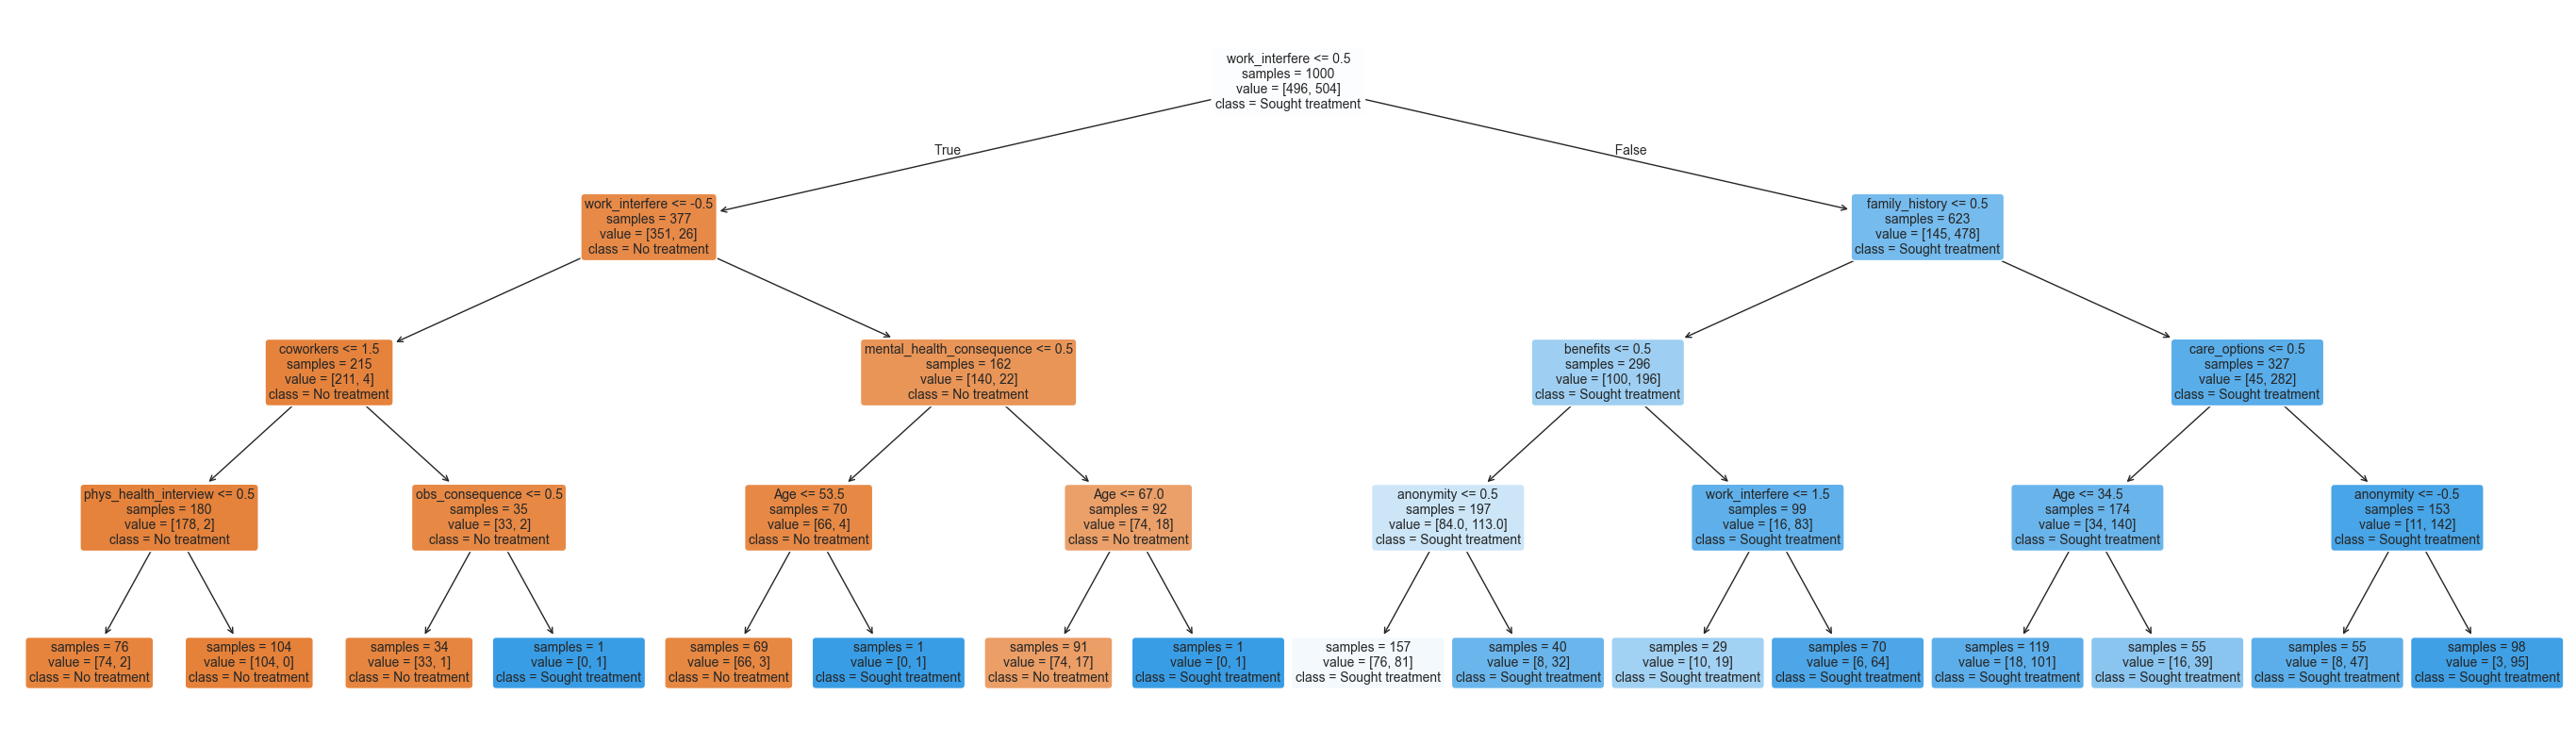

|--- work_interfere <= 0.50
|   |--- work_interfere <= -0.50
|   |   |--- coworkers <= 1.50
|   |   |   |--- phys_health_interview <= 0.50
|   |   |   |   |--- class: No treatment
|   |   |   |--- phys_health_interview >  0.50
|   |   |   |   |--- class: No treatment
|   |   |--- coworkers >  1.50
|   |   |   |--- obs_consequence <= 0.50
|   |   |   |   |--- class: No treatment
|   |   |   |--- obs_consequence >  0.50
|   |   |   |   |--- class: Sought treatment
|   |--- work_interfere >  -0.50
|   |   |--- mental_health_consequence <= 0.50
|   |   |   |--- Age <= 53.50
|   |   |   |   |--- class: No treatment
|   |   |   |--- Age >  53.50
|   |   |   |   |--- class: Sought treatment
|   |   |--- mental_health_consequence >  0.50
|   |   |   |--- Age <= 67.00
|   |   |   |   |--- class: No treatment
|   |   |   |--- Age >  67.00
|   |   |   |   |--- class: Sought treatment
|--- work_interfere >  0.50
|   |--- family_history <= 0.50
|   |   |--- benefits <= 0.50
|   |   |   |--- anonymi

In [208]:
# model creation

# initializing and training the algorithm with a restricted depth to prevent overfitting
dt_clf = DecisionTreeClassifier(random_state=42, max_depth=4)
dt_clf.fit(X_train, y_train)

y_pred_dt = dt_clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")

# show confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No treatment', 'Sought treatment'], yticklabels=['No treatment', 'Sought treatment'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix for decision tree')
plt.show()

print("Classification report:")
print(classification_report(y_test, y_pred_dt))

# sorted according to gini importance
dt_importances = pd.Series(dt_clf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 7 most important features:")
print(dt_importances.head(7).index.tolist())

plt.figure(figsize=(35,10))
plot_tree(dt_clf, feature_names=X.columns, class_names=['No treatment', 'Sought treatment'], filled=True, rounded=True, fontsize=10, impurity=False)
plt.show()

class_names = ['No treatment', 'Sought treatment']
tree_logic_report = export_text(dt_clf, feature_names=list(X.columns), class_names=class_names)
print(tree_logic_report)

In [214]:
# experiment 1: random forest

# 100 trees with max depth of 4 to prevent overfitting and to allow for better interpretability of feature importance
rf_clf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=4)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

print("Experiment 1: random forest classifier")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

rf_importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False)
top_features = rf_importances.head(7).index.tolist()
print("\nSelected top features for subset experiment:")
print(top_features)

Experiment 1: random forest classifier
Accuracy: 0.8280

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.76      0.81       123
           1       0.80      0.89      0.84       127

    accuracy                           0.83       250
   macro avg       0.83      0.83      0.83       250
weighted avg       0.83      0.83      0.83       250


Selected top features for subset experiment:
['work_interfere', 'family_history', 'care_options', 'benefits', 'Gender', 'Age', 'leave']


In [234]:
# experiment 2: logistic regression

# scaler is used to standardize the features for logistic regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_clf = LogisticRegression(random_state=42)
lr_clf.fit(X_train_scaled, y_train)
y_pred_lr = lr_clf.predict(X_test_scaled)

print(f"Logistic regression accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_lr))

print("\nLogistic regression coefficients for all features:")
for feature, coef in zip(list(X.columns), lr_clf.coef_[0]):
    sign = "+" if coef >= 0 else ""
    print(f"  {sign}{coef:.4f} * {feature}")

# we sort by the absolute value to find the strongest drivers, whether positive or negative
lr_coefficients = pd.Series(lr_clf.coef_[0], index=X.columns)
strongest_drivers = lr_coefficients.abs().sort_values(ascending=False).head(7)
print("\nTop 7 strongest drivers:")
print(lr_coefficients.loc[strongest_drivers.index])

Logistic regression accuracy: 0.7920

Classification report:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       123
           1       0.80      0.79      0.79       127

    accuracy                           0.79       250
   macro avg       0.79      0.79      0.79       250
weighted avg       0.79      0.79      0.79       250


Logistic regression coefficients for all features:
  +0.2176 * Age
  +0.2144 * Gender
  -0.1342 * self_employed
  +0.5462 * family_history
  +1.8068 * work_interfere
  +0.0514 * no_employees
  -0.0413 * remote_work
  +0.0864 * tech_company
  +0.3469 * benefits
  +0.3221 * care_options
  -0.0734 * wellness_program
  -0.2688 * seek_help
  +0.2555 * anonymity
  -0.0069 * leave
  +0.0608 * mental_health_consequence
  -0.0192 * phys_health_consequence
  +0.3829 * coworkers
  -0.1196 * supervisor
  +0.0370 * mental_health_interview
  -0.0606 * phys_health_interview
  -0.0032 * mental_vs_physical
  +0.1360 * ob

Gradient boosting accuracy: 0.8400


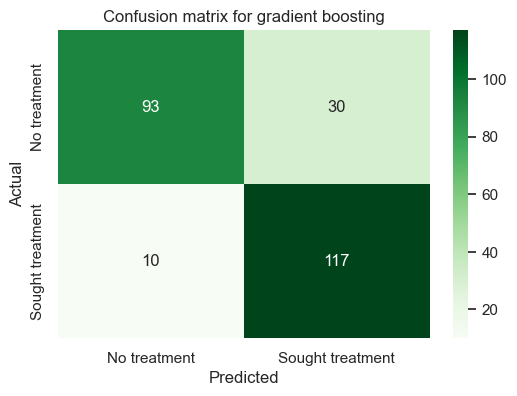

Classification report:
              precision    recall  f1-score   support

           0     0.9029    0.7561    0.8230       123
           1     0.7959    0.9213    0.8540       127

    accuracy                         0.8400       250
   macro avg     0.8494    0.8387    0.8385       250
weighted avg     0.8486    0.8400    0.8388       250


Top 7 most important features:
work_interfere               0.840990
family_history               0.046399
benefits                     0.024856
care_options                 0.021959
Age                          0.021561
anonymity                    0.017795
mental_health_consequence    0.005127
dtype: float64


In [233]:
# experiment 3: gradient boosting

# n_estimators=100 means we are building 100 sequential trees
gb_clf = GradientBoostingClassifier(random_state=42, n_estimators=100, max_depth=4, learning_rate=0.01)
gb_clf.fit(X_train, y_train)

y_pred_gb = gb_clf.predict(X_test)
print(f"Gradient boosting accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")

cm_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens', xticklabels=['No treatment', 'Sought treatment'], yticklabels=['No treatment', 'Sought treatment'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix for gradient boosting')
plt.show()

print("Classification report:")
print(classification_report(y_test, y_pred_gb, digits=4))

gb_importances = pd.Series(gb_clf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 7 most important features:")
print(gb_importances.head(7))